In [1]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
import qkeras
import sys
sys.path.append("../MuC_Smartpix_ML")
sys.path.append("../eric")
sys.path.append("../ryan")
import Model_Classes
from model1 import Model1
from model2 import Model2
from model3 import Model3
from model2_5 import Model2_5
from ASICModel import ModelASIC
import tfLoaderUtils
import distillers
tfRecordFolder="/local/d1/smartpixML/2026Datasets/Data_Files/Data_Set_2026V4_June/TF_Records/filtering_records16384_data_shuffled_single_bigData_normalized/"


sys.path.append("../MuC_Smartpix_Data_Production/tfRecords")
import OptimizedDataGenerator4_data_shuffled_bigData_NewFormat as ODG2

import json
import studentTeacherRunner
import glob

2026-10-16 04:10:51.785092: I tensorflow/core/util/port.cc:110] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2026-10-16 04:10:51.826790: I tensorflow/core/platform/cpu_feature_guard.cc:182] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: SSE4.1 SSE4.2 AVX AVX2 AVX512F AVX512_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


<class 'MuC_Smartpix_ML.Model_Classes.SmartPixModel'>
weird import error
[PhysicalDevice(name='/physical_device:CPU:0', device_type='CPU'), PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
True
True
Instructions for updating:
Use `tf.config.list_physical_devices('GPU')` instead.
True


2026-10-16 04:10:53.964356: I tensorflow/core/common_runtime/gpu/gpu_device.cc:1639] Created device /device:GPU:0 with 1144 MB memory:  -> device: 0, name: NVIDIA RTX A4000, pci bus id: 0000:4b:00.0, compute capability: 8.6


In [4]:

from qkeras import QDense, QActivation, quantized_bits, quantized_relu, quantized_tanh
def constructModel (
            input_bits = 12,
            w_bits = 10,
            rownodes = 20,
            endRowNodes=10):

    input1 = tf.keras.layers.Input(shape=(1,), name="z_global")
    input2 = tf.keras.layers.Input(shape=(1,), name="x_size")
    # input3 = tf.keras.layers.Input(shape=(1,), name="y_size")
    # input4 = tf.keras.layers.Input(shape=(1,), name="y_local")
    # input5 = tf.keras.layers.Input(shape=(1,), name="nModule")
    # input6 = tf.keras.layers.Input(shape=(1,), name="x_local")

    # inputList = [input2, input3, input4, input5, input6]
    inputList = [input2, input1]

    q_input1 = QActivation(activation=quantized_bits(input_bits, 0), name="q_input_1")(input1)
    q_input2 = QActivation(activation=quantized_bits(input_bits, 0), name="q_input_2")(input2)
    # q_input3 = QActivation(activation=quantized_bits(input_bits, 0), name="q_input_3")(input3)
    # q_input4 = QActivation(activation=quantized_bits(input_bits, 0), name="q_input_4")(input4)
    # q_input5 = QActivation(activation=quantized_bits(input_bits, 0), name="q_input_5")(input5)
    # q_input6 = QActivation(activation=quantized_bits(input_bits, 0), name="q_input_6")(input6)

    x_concat1 = tf.keras.layers.Concatenate()([q_input2, q_input1])
    # x_concat2 = tf.keras.layers.Concatenate()([x_concat1, q_input4])
    # x_concat3 = tf.keras.layers.Concatenate()([x_concat2, q_input5])
    # x_concat4 = tf.keras.layers.Concatenate()([x_concat3, q_input6])
    x=x_concat1

    # layer 1
    x = QDense(
    rownodes,
    kernel_quantizer=quantized_bits(w_bits, 0, alpha=1),
    bias_quantizer=quantized_bits(w_bits, 0, alpha=1),
    )(x)
    x = QActivation(
    activation=quantized_relu(8, 0),
    name="q_relu1"
    )(x)
    # layer 1 again
    x = QDense(
    rownodes,
    kernel_quantizer=quantized_bits(w_bits, 0, alpha=1),
    bias_quantizer=quantized_bits(w_bits, 0, alpha=1),
    )(x)
    x = QActivation(
    activation=quantized_relu(8, 0),
    name="q_relu1_2"
    )(x)
    # layer 1 again
    x = QDense(
    rownodes,
    kernel_quantizer=quantized_bits(w_bits, 0, alpha=1),
    bias_quantizer=quantized_bits(w_bits, 0, alpha=1),
    )(x)
    x = QActivation(
    activation=quantized_relu(8, 0),
    name="q_relu1_3"
    )(x)
    ## layer 2
    x = QDense(
    endRowNodes,
    kernel_quantizer=quantized_bits(w_bits, 0, alpha=1),
    bias_quantizer=quantized_bits(w_bits, 0, alpha=1),
    )(x)
    x = QActivation(
    activation=quantized_relu(8, 0),
    name="q_relu2"
    )(x)
    ## output layer
    x = QDense(
    1,
    kernel_quantizer=quantized_bits(w_bits, 0, alpha=1),
    bias_quantizer=quantized_bits(w_bits, 0, alpha=1),
    )(x)


    ## output later
    output = QActivation("quantized_sigmoid(8,0)", name="output_activation")(x)

    model = tf.keras.Model(inputs=inputList, outputs=output)
    return model


In [14]:
smallModel = constructModel()
configName = "justThisOne"
smodel = Model1(tfRecordFolder = tfRecordFolder) 
smodel.models[configName] = smallModel
# smodel.buildModel()

In [17]:
smodel.trainModel(config_name=configName,epochs=100)


Model: "model_6"
__________________________________________________________________________________________________
 Layer (type)                Output Shape                 Param #   Connected to                  
 x_size (InputLayer)         [(None, 1)]                  0         []                            
                                                                                                  
 z_global (InputLayer)       [(None, 1)]                  0         []                            
                                                                                                  
 q_input_2 (QActivation)     (None, 1)                    0         ['x_size[0][0]']              
                                                                                                  
 q_input_1 (QActivation)     (None, 1)                    0         ['z_global[0][0]']            
                                                                                            

/home/dabadjiev/miniconda3/envs/mlgpu_qkeras_tar/lib/python3.8/site-packages/keras/src/engine/functional.py:639: UserWarning: Input dict contained keys ['y_size', 'y_local', 'nModule', 'x_local', 'nPix'] which did not match any model input. They will be ignored by the model.
  inputs = self._flatten_to_reference_inputs(inputs)


162/162 [==============================] - ETA: 0s - loss: 0.3988 - binary_accuracy: 0.8320
[Gradient Monitor] Epoch 0:
  Mean grad norm: 5.01e-02
  Max grad norm: 1.62e-01
  Min grad norm: 6.40e-03
162/162 [==============================] - 13s 69ms/step - loss: 0.3988 - binary_accuracy: 0.8320 - val_loss: 0.3732 - val_binary_accuracy: 0.8433


/home/dabadjiev/miniconda3/envs/mlgpu_qkeras_tar/lib/python3.8/site-packages/keras/src/engine/training.py:3000: UserWarning: You are saving your model as an HDF5 file via `model.save()`. This file format is considered legacy. We recommend using instead the native Keras format, e.g. `model.save('my_model.keras')`.
  saving_api.save_model(


Epoch 2/100
162/162 [==============================] - 11s 67ms/step - loss: 0.3704 - binary_accuracy: 0.8439 - val_loss: 0.3695 - val_binary_accuracy: 0.8432
Epoch 3/100
162/162 [==============================] - 11s 66ms/step - loss: 0.3687 - binary_accuracy: 0.8447 - val_loss: 0.3690 - val_binary_accuracy: 0.8448
Epoch 4/100
162/162 [==============================] - 11s 66ms/step - loss: 0.3680 - binary_accuracy: 0.8451 - val_loss: 0.3681 - val_binary_accuracy: 0.8447
Epoch 5/100
162/162 [==============================] - 11s 66ms/step - loss: 0.3677 - binary_accuracy: 0.8454 - val_loss: 0.3676 - val_binary_accuracy: 0.8455
Epoch 6/100
162/162 [==============================] - ETA: 0s - loss: 0.3678 - binary_accuracy: 0.8454
[Gradient Monitor] Epoch 5:
  Mean grad norm: 4.38e-02
  Max grad norm: 1.51e-01
  Min grad norm: 4.77e-03
162/162 [==============================] - 11s 67ms/step - loss: 0.3678 - binary_accuracy: 0.8454 - val_loss: 0.3674 - val_binary_accuracy: 0.8456
Epoch 

Training history plot saved to ./plots/Model1_training_history.png


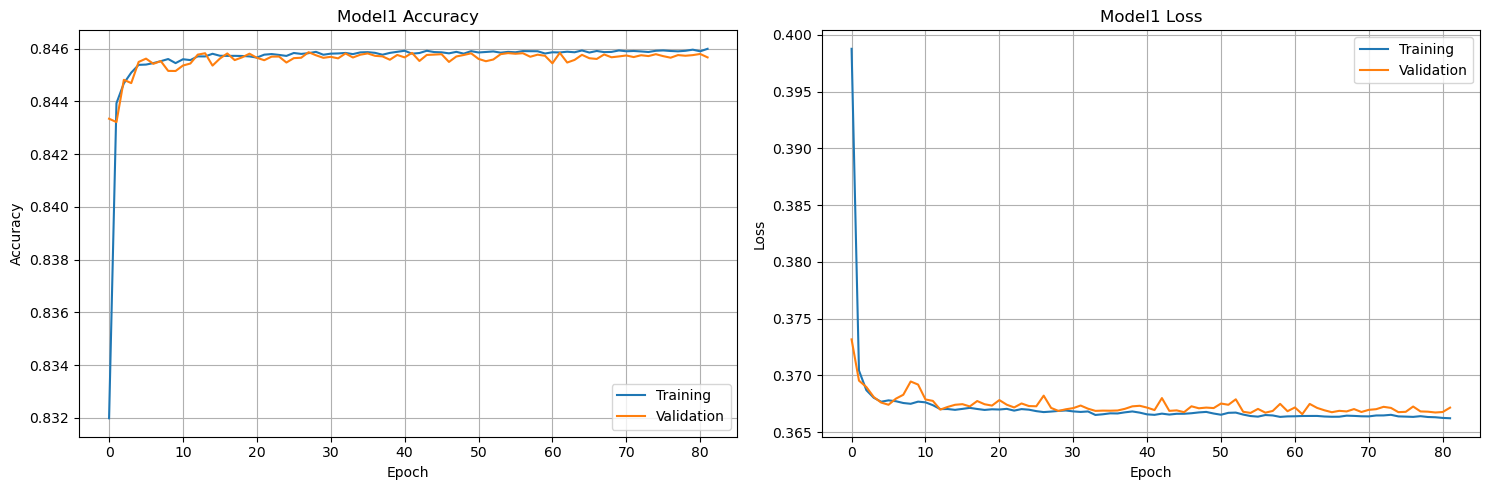

ROC curve plot saved to ./plots/Model1_roc_curve.png


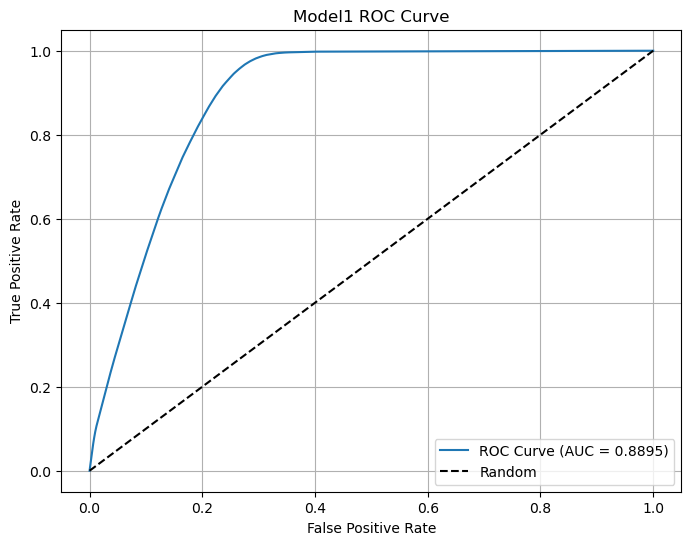

In [19]:
smodel.plotModel(config_name=configName)

In [18]:
smodel.evaluate(config_name=configName,predictionPlots=False,signal_efficiencies=[0.95, 0.98, 0.99])


Evaluating Model1 [justThisOne]...


/home/dabadjiev/miniconda3/envs/mlgpu_qkeras_tar/lib/python3.8/site-packages/keras/src/engine/functional.py:639: UserWarning: Input dict contained keys ['y_size', 'y_local', 'nModule', 'x_local', 'nPix'] which did not match any model input. They will be ignored by the model.
  inputs = self._flatten_to_reference_inputs(inputs)


41/41 [==============================] - 3s 56ms/step
Data rate at fpr 0.2599707928560414 and threshold [0.546875]
Data rate at fpr 0.2929966348290656 and threshold [0.3828125]
Data rate at fpr 0.31468429979954105 and threshold [0.26171875]
✓ Model1 evaluation completed!
  Test Loss: 0.3666
  Test Accuracy: 0.8458
  ROC AUC: 0.8895

  Background Rejection Metrics (Bkg Rej = 1 - FPR):
    @ 95% signal efficiency: Bkg Rej = 0.7400 (FPR = 0.259971), Back Data Accep = 0.2282
    @ 98% signal efficiency: Bkg Rej = 0.7070 (FPR = 0.292997), Back Data Accep = 0.2592
    @ 99% signal efficiency: Bkg Rej = 0.6853 (FPR = 0.314684), Back Data Accep = 0.2799


{'test_loss': 0.36658909916877747,
 'test_accuracy': 0.8458400964736938,
 'roc_auc': 0.8894985521609334,
 'fpr': [0.0,
  1.8141083204078116e-05,
  0.00012396406856120045,
  0.0005714441209284607,
  0.0016387445161017231,
  0.0031081722556320504,
  0.004474800523672602,
  0.005690253098345836,
  0.0065096253563966975,
  0.007183868948814934,
  0.008145346358631074,
  0.008487003425641211,
  0.009112870796181907,
  0.009421269210651236,
  0.01002294847025316,
  0.010609510160518351,
  0.011144672115038655,
  0.011250495100395778,
  0.01155587000099776,
  0.012242207648885381,
  0.013146238295221942,
  0.014503796021660454,
  0.017049594697966082,
  0.02078363432413883,
  0.02632573524298469,
  0.03160479045537142,
  0.037107585693941784,
  0.044711723070317864,
  0.05133019492593903,
  0.06380521314261008,
  0.07335951696342455,
  0.0821095660955249,
  0.09122546040557415,
  0.09712735947463423,
  0.10211313384188836,
  0.10761592908045872,
  0.11355108680205962,
  0.11781424135501797,
 